# Notebook 05 — RQ2 (Check): Do Google searches follow real migration?

**Project:** Searching for Work in Germany: Google Trends Signals of Labour Migration Interest and Policy Effects (focus: migrant care workers)
**Author:** Tayaphon Rodsai · MSc Data Science for Society and Business, Constructor University

---

### The question

> **RQ2:** Does search interest in working in Germany follow the number of first permits by country of origin (2015–2025)?

If searches go **up and down together with** the real permit numbers, Google Trends is a useful **early signal** of migration. If not, searches show something else (for example interest that does not lead to a move).

### Why we do not need `gtab` here

RQ2 compares each keyword **with itself over time** (search in year *t* vs. permits in year *t*). A **correlation does not change** when a series is multiplied by a constant, so the 0–100 scaling of Google Trends does not matter. `gtab` is only needed to compare **between** keywords and countries (RQ1).

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")
ROUND2 = RAW / "gt_keywords" / "round2"

CODES = {
    "IN": "India", "TR": "Türkiye", "VN": "Viet Nam", "MA": "Morocco", "TN": "Tunisia",
    "PH": "Philippines", "ID": "Indonesia", "BA": "Bosnia and Herzegovina", "CM": "Cameroon",
}
YEARS = list(range(2015, 2026))          # permits are available up to 2025

## 2. Permit data for 2015–2025

Notebook 01 only downloaded 2023–2025. For RQ2 we need **all years from 2015**. We download two Eurostat tables for the 9 countries:

| Table | Reason | Matches which keyword theme |
|---|---|---|
| `migr_resfirst` | Employment (`EMP`) | **work** |
| `migr_resedu` | Other educational reasons (`EDUC_OTH`, incl. Ausbildung) | **training** |
| both together | work + other education ("care route", see Notebook 01) | **care** |

In [2]:
def eurostat_url(table, reason):
    params = {
        "c[freq]": "A", "c[reason]": reason, "c[citizen]": ",".join(CODES),
        "c[duration]": "TOTAL", "c[unit]": "PER", "c[geo]": "DE",
        "c[TIME_PERIOD]": ",".join(map(str, YEARS)),
        "compress": "false", "format": "csvdata", "formatVersion": "1.0", "lang": "en", "labels": "label_only",
    }
    query = "&".join(f"{k}={v}" for k, v in params.items())
    return f"https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/{table}/1.0/*.*.*.*.*.*?{query}"


def load_eurostat(url, file):
    """Load a saved snapshot if it exists; otherwise download from Eurostat and save it."""
    if file.exists():
        print("Loaded saved snapshot:", file.name)
        return pd.read_csv(file)
    data = pd.read_csv(url)
    data.to_csv(file, index=False)
    print("Downloaded from Eurostat and saved:", file.name)
    return data


raw_emp = load_eurostat(eurostat_url("migr_resfirst", "EMP"), RAW / "eurostat_migr_resfirst_DE_EMP_9countries_2015_2025.csv")
raw_oth = load_eurostat(eurostat_url("migr_resedu", "EDUC_OTH"), RAW / "eurostat_migr_resedu_DE_EDUC_OTH_9countries_2015_2025.csv")


def to_table(raw_data):
    """One row per year, one column per country."""
    return raw_data.pivot_table(index="TIME_PERIOD", columns="citizen", values="OBS_VALUE").reindex(YEARS)


permits = {
    "work": to_table(raw_emp),
    "training": to_table(raw_oth),
}
permits["care"] = permits["work"] + permits["training"]
permits["work"]

Loaded saved snapshot: eurostat_migr_resfirst_DE_EMP_9countries_2015_2025.csv
Loaded saved snapshot: eurostat_migr_resedu_DE_EDUC_OTH_9countries_2015_2025.csv


citizen,Bosnia and Herzegovina,Cameroon,India,Indonesia,Morocco,Philippines,Tunisia,Türkiye,Viet Nam
TIME_PERIOD,,,,,,,,,
2015,1062.0,69.0,1933.0,111.0,56.0,63.0,66.0,555.0,62.0
2016,4414.0,99.0,4491.0,295.0,97.0,364.0,202.0,1283.0,189.0
2017,6193.0,108.0,5422.0,332.0,143.0,511.0,278.0,1805.0,261.0
2018,6335.0,91.0,7655.0,458.0,220.0,762.0,347.0,2427.0,424.0
2019,6833.0,154.0,8283.0,726.0,273.0,1316.0,551.0,3255.0,439.0
2020,5058.0,119.0,5027.0,360.0,214.0,1310.0,401.0,2376.0,355.0
2021,3076.0,236.0,7161.0,1026.0,392.0,1943.0,854.0,3633.0,511.0
2022,6172.0,310.0,12902.0,1120.0,571.0,2416.0,1377.0,5771.0,728.0
2023,6753.0,328.0,12289.0,1205.0,808.0,2474.0,1798.0,6424.0,767.0


**Check:** India 2025 in the work table should be **11,069** (the same as Notebook 01).

## 3. Search data: yearly averages

We use the **final keywords** from Notebook 02 and the monthly series downloaded in round 2. Permits are yearly, so we take the **yearly average** of the monthly search values. 2026 is not used (no permit data yet).

In [3]:
final = pd.read_csv(PROCESSED / "keywords_final.csv")
final["file"] = final["code"] + "_" + final["theme"] + np.where(final["attempt"] == "alt", "_alt", "")

monthly = {}
for _, k in final.iterrows():
    s = pd.read_csv(ROUND2 / f"{k['file']}.csv", parse_dates=["Time"], index_col="Time").iloc[:, 0]
    monthly[k["file"]] = s.replace("<1", 0.5).astype(float)
monthly = pd.DataFrame(monthly)

yearly_search = monthly.groupby(monthly.index.year).mean().reindex(YEARS)
yearly_search.round(1)

,BA_work,CM_training_alt,CM_work_alt,IN_training,IN_work,ID_care,ID_training,ID_work,MA_training_alt,MA_work_alt,PH_care,PH_work,TN_training_alt,TN_work_alt,TR_care,TR_training,TR_work,VN_care,VN_training,VN_work
Time,,,,,,,,,,,,,,,,,,,,
2015,50.2,0.0,7.6,0.0,54.2,0.0,0.0,30.8,0.0,44.1,2.9,31.3,0.4,45.2,0.0,0.0,7.8,33.6,0.8,6.1
2016,66.2,0.0,46.2,0.0,39.8,2.9,0.0,27.5,0.5,37.4,19.4,30.7,0.0,47.3,0.0,0.0,7.7,41.9,4.8,0.0
2017,65.8,0.0,30.9,0.0,40.4,2.4,0.6,24.8,1.5,40.8,42.6,33.8,0.6,49.4,0.0,0.0,9.6,52.3,6.4,28.2
2018,61.8,2.4,18.3,0.0,37.6,2.2,6.1,25.8,6.4,54.5,49.3,31.9,2.7,46.1,16.8,0.0,24.6,45.8,10.1,10.9
2019,44.7,5.9,46.4,0.0,38.0,9.9,16.1,28.4,23.0,73.2,41.6,26.2,9.3,60.2,12.5,0.0,28.8,45.6,18.2,22.1
2020,22.5,4.2,18.2,0.0,34.0,6.3,12.5,37.8,21.8,29.3,33.6,18.3,13.1,35.8,11.7,0.0,24.1,42.5,16.2,10.8
2021,14.8,9.2,18.7,3.2,38.4,16.4,18.4,46.1,28.5,21.8,38.4,13.3,21.2,40.4,20.3,12.7,36.8,46.2,29.5,15.7
2022,14.9,28.0,36.4,16.9,45.5,27.7,22.8,54.2,44.8,55.1,39.0,29.0,29.9,72.4,23.1,33.9,53.6,61.7,26.8,30.4
2023,7.8,35.2,41.8,29.8,45.4,37.4,28.0,53.8,66.0,55.5,38.2,27.0,40.2,70.5,23.6,39.1,59.4,72.2,61.1,63.2


## 4. Put searches and permits side by side

For each final keyword, we pair the yearly searches with the matching permits (by country and theme). Years where a keyword has **no data** (yearly average = 0) are left out, because 0 there means "too few searches for Google to show", not "no interest".

In [4]:
rows = []
for _, k in final.iterrows():
    for year in YEARS:
        rows.append({
            "file": k["file"], "country": k["country"], "theme": k["theme"], "keyword": k["keyword"],
            "year": year,
            "search": yearly_search.loc[year, k["file"]],
            "permits": permits[k["theme"]].loc[year, k["country"]],
        })
pairs = pd.DataFrame(rows)
pairs = pairs[(pairs["search"] > 0) & pairs["permits"].notna()]
pairs.head()

,file,country,theme,keyword,year,search,permits
0,BA_work,Bosnia and Herzegovina,work,posao u njemačkoj,2015,50.250000,1062.0
1,BA_work,Bosnia and Herzegovina,work,posao u njemačkoj,2016,66.250000,4414.0
2,BA_work,Bosnia and Herzegovina,work,posao u njemačkoj,2017,65.750000,6193.0
3,BA_work,Bosnia and Herzegovina,work,posao u njemačkoj,2018,61.833333,6335.0
4,BA_work,Bosnia and Herzegovina,work,posao u njemačkoj,2019,44.666667,6833.0


## 5. Correlation per keyword

For each keyword we compute:

| Measure | Question |
|---|---|
| **Pearson r** | Do searches and permits move together (linear)? |
| **Spearman ρ** | The same, but only using the **ranking** of years (less sensitive to one extreme year) |
| **Lag r** | Do searches in year *t* match permits in year ***t + 1***? ("searches come first") |
| **r without 2024** | Is the result driven by the unusual 2024 permit drop (Notebook 01)? |

With only 4–11 years per keyword, a single correlation is **uncertain**. We therefore only compute it for keywords with **at least 6 years**, and we look at the overall pattern rather than single numbers.

In [5]:
MIN_YEARS = 6


def correlations(g):
    g = g.sort_values("year")
    out = {"country": g["country"].iloc[0], "theme": g["theme"].iloc[0], "keyword": g["keyword"].iloc[0],
           "years": len(g), "from": int(g["year"].min()), "to": int(g["year"].max())}
    if len(g) < MIN_YEARS:
        return out
    out["pearson_r"] = g["search"].corr(g["permits"])
    out["spearman_rho"] = g["search"].rank().corr(g["permits"].rank())   # Spearman = correlation of the ranks
    lagged = g.set_index("year")
    lag = pd.concat([lagged["search"], lagged["permits"].shift(-1)], axis=1).dropna()   # search t vs permits t+1
    out["lag_r"] = lag["search"].corr(lag["permits"]) if len(lag) >= MIN_YEARS - 1 else np.nan
    no24 = g[g["year"] != 2024]
    out["r_without_2024"] = no24["search"].corr(no24["permits"])
    return out


# one row per keyword (built from a dictionary, so it works with every pandas version)
results = pd.DataFrame.from_dict({file: correlations(g) for file, g in pairs.groupby("file")}, orient="index")
results = results.sort_values(["theme", "pearson_r"], ascending=[True, False])
results.round(2)

,country,theme,keyword,years,from,to,pearson_r,spearman_rho,lag_r,r_without_2024
ID_care,Indonesia,care,perawat jerman,10,2016,2025,0.93,0.88,0.81,0.95
VN_care,Viet Nam,care,điều dưỡng đức,11,2015,2025,0.76,0.85,0.79,0.78
PH_care,Philippines,care,nurse germany,11,2015,2025,0.54,0.28,0.55,0.52
TR_care,Türkiye,care,almanya hemşire,8,2018,2025,0.06,0.14,0.53,0.09
MA_training_alt,Morocco,training,ausbildung,10,2016,2025,0.97,0.98,0.97,0.96
TN_training_alt,Tunisia,training,ausbildung,10,2015,2025,0.93,0.93,0.95,0.96
ID_training,Indonesia,training,ausbildung jerman,9,2017,2025,0.93,0.93,0.89,0.94
CM_training_alt,Cameroon,training,ausbildung,8,2018,2025,0.84,0.86,0.94,0.82
VN_training,Viet Nam,training,du học nghề đức,11,2015,2025,0.77,0.95,0.81,0.80
IN_training,India,training,ausbildung in germany,5,2021,2025,NaN,NaN,NaN,NaN


## 6. All keywords together (pooled)

Single keywords have few years. To get one overall answer, we **standardise** each series within its keyword (z-score: mean 0, standard deviation 1) and pool all keywords with at least 6 years. Then each point is "a year that was above or below normal" for both searches and permits.

In [6]:
usable_files = results[results["years"] >= MIN_YEARS].index
pooled = pairs[pairs["file"].isin(usable_files)].copy()
z = lambda s: (s - s.mean()) / s.std()
pooled["search_z"] = pooled.groupby("file")["search"].transform(z)
pooled["permits_z"] = pooled.groupby("file")["permits"].transform(z)

r_all = pooled["search_z"].corr(pooled["permits_z"])
print(f"Pooled correlation (all themes): r = {r_all:.2f}  (n = {len(pooled)} keyword-years, {pooled['file'].nunique()} keywords)")
for theme, g in pooled.groupby("theme"):
    print(f"  {theme:9s} r = {g['search_z'].corr(g['permits_z']):.2f}  (n = {len(g)})")

Pooled correlation (all themes): r = 0.54  (n = 185 keyword-years, 18 keywords)
  care      r = 0.61  (n = 40)
  training  r = 0.88  (n = 48)
  work      r = 0.35  (n = 97)


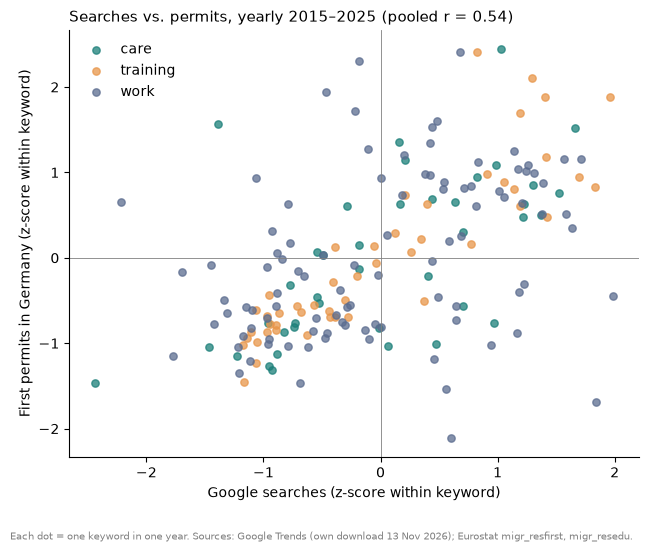

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
colors = {"care": "#1B7F79", "training": "#E8964A", "work": "#5B6C8F"}
for theme, g in pooled.groupby("theme"):
    ax.scatter(g["search_z"], g["permits_z"], color=colors[theme], label=theme, alpha=0.75, s=28)
ax.axhline(0, color="grey", linewidth=0.6); ax.axvline(0, color="grey", linewidth=0.6)
ax.set_xlabel("Google searches (z-score within keyword)")
ax.set_ylabel("First permits in Germany (z-score within keyword)")
ax.set_title(f"Searches vs. permits, yearly 2015–2025 (pooled r = {r_all:.2f})", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
fig.subplots_adjust(bottom=0.16)
fig.text(0.01, 0.01, "Each dot = one keyword in one year. Sources: Google Trends (own download 13 Nov 2026); Eurostat migr_resfirst, migr_resedu.",
         fontsize=7.5, color="grey")
fig.savefig(FIGURES / "05_rq2_pooled_scatter.png", dpi=200)
plt.show()

## 7. Look at each country

The chart shows searches (line) and permits (bars) for the **work** keyword in every country, both scaled to their own maximum = 100, so that the **shapes** can be compared.

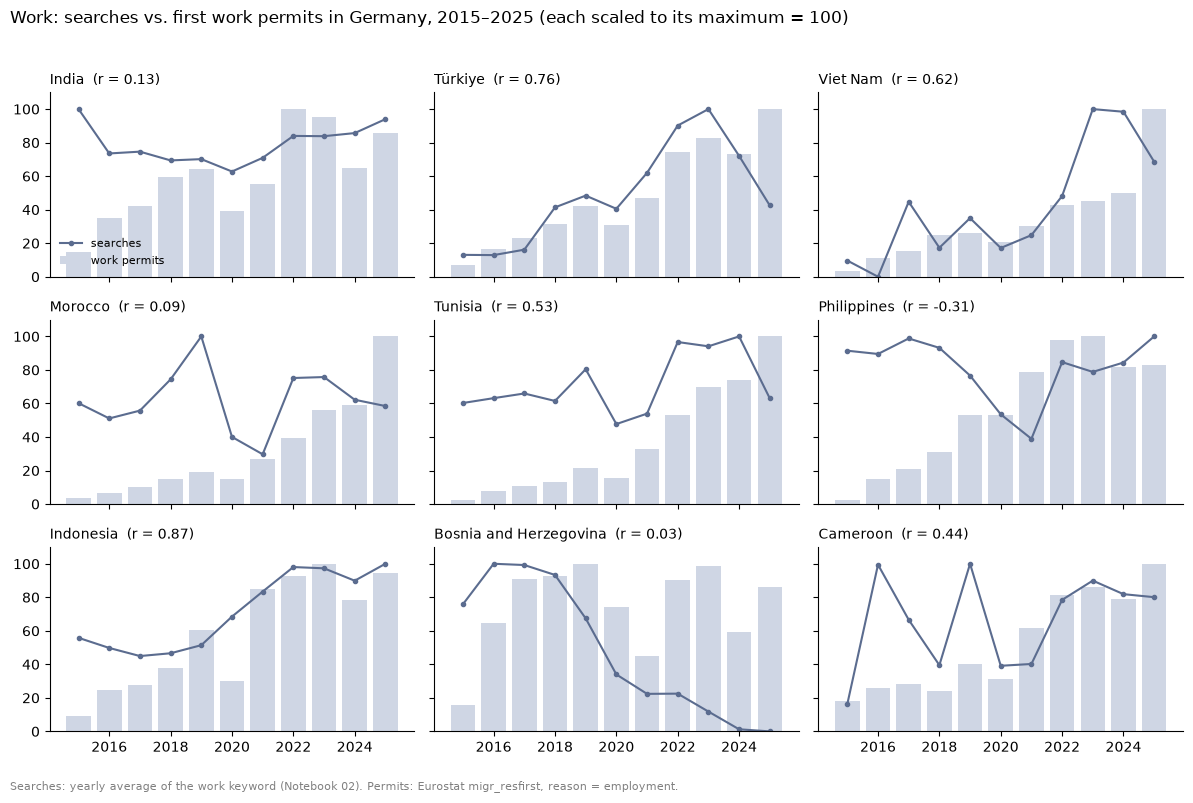

In [8]:
work = final[final["theme"] == "work"].set_index("country")

fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True, sharey=True)
for ax, country in zip(axes.flat, CODES.values()):
    file = work.loc[country, "file"]
    s = yearly_search[file]
    p = permits["work"][country]
    ax.bar(p.index, p / p.max() * 100, color="#CFD6E4", label="work permits")
    ax.plot(s.index, s / s.max() * 100, color="#5B6C8F", marker="o", markersize=3, label="searches")
    r = results.loc[file, "pearson_r"] if file in results.index else np.nan
    ax.set_title(f"{country}  (r = {r:.2f})" if pd.notna(r) else country, fontsize=10, loc="left")
    ax.set_ylim(0, 110)
    ax.spines[["top", "right"]].set_visible(False)

axes.flat[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Work: searches vs. first work permits in Germany, 2015–2025 (each scaled to its maximum = 100)",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
fig.text(0.01, 0.005, "Searches: yearly average of the work keyword (Notebook 02). Permits: Eurostat migr_resfirst, reason = employment.",
         fontsize=8, color="grey")
fig.savefig(FIGURES / "05_rq2_work_by_country.png", dpi=200)
plt.show()

---
## 8. Robustness: is it more than a common trend?

**The problem.** From 2015 to 2025, migration to Germany grew for almost **all** countries, and so did internet use and searches. Two series that both grow will always look correlated, even if they are not linked. This is called a **common trend** (or a *spurious correlation*). COVID (2020) and the 2024 dip also hit all countries at the same time.

So we test three stricter versions:

| Test | Question | Removes |
|---|---|---|
| **A. Yearly changes** | Do searches rise **in the years when** permits rise? | long-term growth |
| **B. Regression with year fixed effects** | Is a country *above its normal level* in searches when it is *above its normal level* in permits, **compared with the other countries in the same year**? | everything that hits all countries in a year (common trend, COVID, 2024) |
| **C. Placebo** | Do a country's searches fit **its own** permits better than **other countries'** permits? | if not, the link is only a general trend |

### A. Yearly changes

In [9]:
chg = pooled.sort_values(["file", "year"]).copy()
chg["gap"] = chg.groupby("file")["year"].diff()
chg["search_change"] = chg.groupby("file")["search"].pct_change()
chg["permits_change"] = chg.groupby("file")["permits"].pct_change()
chg = chg[chg["gap"] == 1].dropna(subset=["search_change", "permits_change"])   # only consecutive years
chg["search_change_z"] = chg.groupby("file")["search_change"].transform(z)
chg["permits_change_z"] = chg.groupby("file")["permits_change"].transform(z)

r_change = chg["search_change_z"].corr(chg["permits_change_z"])
print(f"Yearly changes, all themes: r = {r_change:.2f}  (n = {len(chg)})")
for theme, g in chg.groupby("theme"):
    print(f"  {theme:9s} r = {g['search_change_z'].corr(g['permits_change_z']):.2f}  (n = {len(g)})")

Yearly changes, all themes: r = 0.30  (n = 165)
  care      r = 0.54  (n = 36)
  training  r = 0.43  (n = 42)
  work      r = 0.13  (n = 87)


### B. Regression with year fixed effects

`C(year)` adds one dummy per year, so everything that is the **same for all countries in a year** is removed. Standard errors are **clustered by keyword**, because the years of one keyword are not independent. The coefficient says: *if searches are 1 standard deviation above normal, permits are … standard deviations above normal*.

In [10]:
import statsmodels.formula.api as smf


def fit(data, y, x):
    formula = f"{y} ~ {x} + C(year)"          # C(year) = year fixed effects
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["file"]})


rows = []
for label, data, y, x in [("levels", pooled, "permits_z", "search_z"),
                          ("yearly changes", chg, "permits_change_z", "search_change_z")]:
    for theme in ["all", "care", "training", "work"]:
        d = data if theme == "all" else data[data["theme"] == theme]
        m = fit(d, y, x)
        lo, hi = m.conf_int().loc[x]
        rows.append({"model": label, "theme": theme, "coef": m.params[x], "ci_low": lo, "ci_high": hi,
                     "p_value": m.pvalues[x], "n": int(m.nobs), "keywords": d["file"].nunique()})
regression = pd.DataFrame(rows)
regression.round(3)

,model,theme,coef,ci_low,ci_high,p_value,n,keywords
0,levels,all,0.053,-0.120,0.226,0.546,185,18
1,levels,care,-0.010,-0.078,0.058,0.776,40,4
2,levels,training,0.198,-0.008,0.404,0.059,48,5
3,levels,work,0.018,-0.239,0.275,0.891,97,9
4,yearly changes,all,0.081,-0.051,0.213,0.231,165,18
5,yearly changes,care,0.229,-0.021,0.478,0.073,36,4
6,yearly changes,training,0.114,-0.242,0.469,0.532,42,5
7,yearly changes,work,-0.069,-0.255,0.116,0.463,87,9


### C. Placebo test

For each keyword we correlate its searches with the permits of **its own country** (real) and with the permits of **every other country** (placebo). If the real correlation is not clearly higher, the link comes from a trend that all countries share.

In [11]:
placebo_rows = []
for _, k in final[final["file"].isin(usable_files)].iterrows():
    s = yearly_search[k["file"]]
    s = s[s > 0]
    for other in CODES.values():
        p = permits[k["theme"]][other].reindex(s.index)
        both = pd.concat([s, p], axis=1).dropna()
        if len(both) >= MIN_YEARS:
            placebo_rows.append({"file": k["file"], "theme": k["theme"], "own_country": other == k["country"],
                                 "r": both.iloc[:, 0].corr(both.iloc[:, 1])})
placebo = pd.DataFrame(placebo_rows)

placebo_summary = placebo.groupby(["theme", "own_country"])["r"].mean().unstack().rename(
    columns={True: "own country (real)", False: "other countries (placebo)"})
placebo_summary["difference"] = placebo_summary["own country (real)"] - placebo_summary["other countries (placebo)"]
placebo_summary.round(2)

own_country,other countries (placebo),own country (real),difference
theme,,,
care,0.54,0.58,0.03
training,0.66,0.89,0.23
work,0.31,0.35,0.04


### D. Sampling noise: does a new Google sample change the result?

Google Trends does not count all searches. It takes a **random sample** each time, so a second download gives slightly different numbers. We downloaded **three keywords a second time** on a different day (14 Nov 2026), chosen to cover different strengths:

| Keyword | Country | Why |
|---|---|---|
| điều dưỡng đức | Viet Nam | strong keyword (no zero months) |
| almanya hemşire | Türkiye | medium keyword (32% zero months) |
| ausbildung | Morocco | training, the strongest RQ2 result |

Files: `data/raw/gt_keywords/repeat/*_s2.csv` (sample 2); sample 1 = round 2.

We check (1) how much the monthly values differ, and (2) whether the **RQ2 correlation** changes with sample 2 or with the **average** of both samples.

In [ ]:
REPEAT = RAW / "gt_keywords" / "repeat"


def read_series(path):
    s = pd.read_csv(path, parse_dates=["Time"], index_col="Time").iloc[:, 0]
    return s.replace("<1", 0.5).astype(float)


noise_rows = []
for file in ["VN_care", "TR_care", "MA_training_alt"]:
    s1 = read_series(ROUND2 / f"{file}.csv")
    s2 = read_series(REPEAT / f"{file}_s2.csv")
    both = (s1 > 0) & (s2 > 0)
    k = final.set_index("file").loc[file]

    # RQ2 correlation with sample 1, sample 2 and the average of both
    r = {}
    for name, s in [("sample 1", s1), ("sample 2", s2), ("average", (s1 + s2) / 2)]:
        y = s.groupby(s.index.year).mean().reindex(YEARS)
        p = permits[k["theme"]][k["country"]]
        d = pd.concat([y, p], axis=1).dropna()
        d = d[d.iloc[:, 0] > 0]
        r[name] = d.iloc[:, 0].corr(d.iloc[:, 1])

    noise_rows.append({
        "keyword": k["keyword"], "country": k["country"],
        "mean_abs_diff": (s1 - s2).abs().mean(),                                   # points on the 0–100 scale
        "mean_rel_diff_%": ((s1 - s2).abs() / ((s1 + s2) / 2))[both].mean() * 100,  # only months with data in both
        "corr_s1_s2_monthly": s1.corr(s2),
        "rq2_r_sample1": r["sample 1"], "rq2_r_sample2": r["sample 2"], "rq2_r_average": r["average"],
    })

noise = pd.DataFrame(noise_rows)
noise.round(3)

**How to read it**
- `mean_abs_diff`: average monthly difference in points (0–100 scale).
- `mean_rel_diff_%`: the same as a percentage — this shows that **small values are noisier** (rounding to whole numbers matters more when a value is 2 than when it is 70).
- `corr_s1_s2_monthly`: how similar the two monthly series are (1 = identical shape).
- `rq2_r_…`: the RQ2 correlation with permits using each sample. If these are close, **sampling noise does not change the RQ2 answer**.

---
## 9. Findings

**RQ2 answer (short):** Google searches **move together with** first permits — but much of this link is a **trend shared by all countries**. A clear **country-specific** signal appears only for **training (Ausbildung)** and, more weakly, for **care**.

**1. Simple correlations are strong.** Pooled over 18 keywords and 185 keyword-years, **r = 0.54** (care 0.61, training 0.88, work 0.35). 17 of 18 keywords are positive and 12 are above 0.5. Removing 2024 hardly changes this (0.52).

**2. Specific keywords work better than general ones.** The strongest links are for training and care keywords (e.g. *ausbildung* in Morocco 0.97 and Tunisia 0.93, *perawat jerman* in Indonesia 0.93, *điều dưỡng đức* in Viet Nam 0.76). General keywords are weak: *jobs in germany* in India (0.13) and the Philippines (−0.31), where many searches are about IT and engineering jobs.

**3. But a large part is a common trend.**
- **Yearly changes** are still positive (r = 0.30), mainly for care (0.54) and training (0.43), not for work (0.13).
- With **year fixed effects**, the coefficients become small and mostly not significant: training 0.20 (p = 0.06), care in yearly changes 0.23 (p = 0.07), work close to 0.
- In the **placebo test**, searches fit **other** countries' permits almost as well as their own for care and work. Only **training** fits its own country clearly better (difference 0.23).

**4. Sampling noise does not change the answer.** A second Google sample (downloaded on another day) differs by about 2–7% per month, but the RQ2 correlation changes by **at most 0.015** (Viet Nam 0.76 → 0.76, Türkiye 0.06 → 0.08, Morocco 0.97 → 0.97).

**Interpretation.** Searches mainly capture **Germany's general pull** over time (growing demand, new rules, COVID), which is the same for all origin countries. **Country-specific** changes are only visible for the Ausbildung route, which grew very differently between countries (e.g. strongly in Viet Nam, Morocco and Cameroon).

**Timing.** Searches in year *t* fit permits in year *t + 1* about as well as in the same year (pooled lag r = 0.55). With yearly data, we cannot show that searches come **first**; monthly or quarterly permit data would be needed.

**Limitations.** Only 6–11 years per keyword and 18 keywords, so tests have little power and confidence intervals are wide. Google Trends values are samples (small differences between downloads). Google changed its data collection in 2016 and 2022. Correlation does not show cause.

*Related work:* Böhme, Gröger & Stöhr (2020) showed that Google search data can help predict international migration flows (*Journal of Development Economics*, 142, 102347). This notebook tests a similar idea for care migration to Germany, with stricter checks for common trends.

## 10. Save results

In [12]:
pairs.to_csv(PROCESSED / "rq2_pairs_search_permits.csv", index=False)
results.to_csv(PROCESSED / "rq2_correlations.csv")
regression.to_csv(PROCESSED / "rq2_regression_year_fe.csv", index=False)
placebo.to_csv(PROCESSED / "rq2_placebo.csv", index=False)
noise.to_csv(PROCESSED / "rq2_sampling_noise.csv", index=False)
print("Saved to", PROCESSED.resolve())

Saved to C:\Users\Tayami\Downloads\F26_MDSSB-CAP-01_Capstone Project\data\processed
